# First subscription renewal analysis

Исследование реализовано по `analyses/first_subscription_renewal/design.md`.

Когорта из дизайна: первая подписка началась в период `[2026-01-01; 2026-04-30]`. Первая подписка определяется по всей таблице подписок до фильтрации когорты. Продление наблюдается в течение 7 дней после окончания первой подписки.

SQL для сборки user-level датасета: `analyses/first_subscription_renewal/sql/01_user_dataset.sql`.

В notebook используются только агрегированные результаты, полученные read-only SQL-запросами через `fmedia_gp`; сырые события и списки `user_id` не выгружались.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Data checks

In [2]:
overall = pd.DataFrame([{
    "analysis_date": "2026-07-02",
    "users": 69518,
    "renewal_rate": 0.2879110446,
    "min_first_sub_start": "2026-01-01 00:00:00",
    "max_first_sub_start": "2026-04-30 00:00:00",
    "max_first_sub_end": "2026-06-03 00:00:00",
    "censored_users": 0,
    "avg_total_watch_hours": 4.8689030459,
    "avg_active_days": 4.4421588653,
    "avg_sessions_cnt": 34.3935383642,
    "avg_distinct_titles": 8.1919934405,
    "avg_distinct_genres": 2.8121349866,
    "share_viewed_first_24h": 0.8451767887,
    "share_viewed_last_3d": 0.1169912828,
    "share_has_tv": 0.2689663109,
}])
overall

,analysis_date,users,renewal_rate,min_first_sub_start,max_first_sub_start,max_first_sub_end,censored_users,avg_total_watch_hours,avg_active_days,avg_sessions_cnt,avg_distinct_titles,avg_distinct_genres,share_viewed_first_24h,share_viewed_last_3d,share_has_tv
0,2026-07-02,69518,0.2879,2026-01-01 00:00:00,2026-04-30 00:00:00,2026-06-03 00:00:00,0,4.8689,4.4422,34.3935,8.1920,2.8121,0.8452,0.1170,0.2690


In [3]:
feature_snapshot = overall[[
    "users", "renewal_rate", "avg_total_watch_hours", "avg_active_days",
    "avg_sessions_cnt", "avg_distinct_titles", "avg_distinct_genres",
    "share_viewed_first_24h", "share_viewed_last_3d", "share_has_tv"
]].T.rename(columns={0: "value"})
feature_snapshot

,value
users,69518.0000
renewal_rate,0.2879
avg_total_watch_hours,4.8689
avg_active_days,4.4422
avg_sessions_cnt,34.3935
avg_distinct_titles,8.1920
avg_distinct_genres,2.8121
share_viewed_first_24h,0.8452
share_viewed_last_3d,0.1170
share_has_tv,0.2690


## 2. Binning and segment tables

In [4]:
watch_hours = pd.DataFrame([
    {"segment": "0", "users": 8022, "renewal_rate": 0.3755921217},
    {"segment": "0-1", "users": 12936, "renewal_rate": 0.2394094001},
    {"segment": "1-3", "users": 21488, "renewal_rate": 0.2705230827},
    {"segment": "3-10", "users": 19592, "renewal_rate": 0.2907309106},
    {"segment": "10+", "users": 7480, "renewal_rate": 0.3203208556},
])

active_days = pd.DataFrame([
    {"segment": "0", "users": 6822, "renewal_rate": 0.3975373791},
    {"segment": "1", "users": 16241, "renewal_rate": 0.2876670156},
    {"segment": "2-3", "users": 19377, "renewal_rate": 0.2571089436},
    {"segment": "4-7", "users": 15482, "renewal_rate": 0.2525513500},
    {"segment": "8+", "users": 11596, "renewal_rate": 0.3224387720},
])

first_24h = pd.DataFrame([
    {"segment": "no", "users": 10763, "renewal_rate": 0.3407042646},
    {"segment": "yes", "users": 58755, "renewal_rate": 0.2782401498},
])

last_3d = pd.DataFrame([
    {"segment": "no", "users": 61385, "renewal_rate": 0.2829681518},
    {"segment": "yes", "users": 8133, "renewal_rate": 0.3252182466},
])

consumption = pd.DataFrame([
    {"segment": "No views", "users": 6822, "renewal_rate": 0.3975373791},
    {"segment": "TV only", "users": 2072, "renewal_rate": 0.3479729730},
    {"segment": "VOD only", "users": 43998, "renewal_rate": 0.2578753580},
    {"segment": "VOD + TV", "users": 16626, "renewal_rate": 0.3149284254},
])

subscription_type = pd.DataFrame([
    {"segment": "paid", "users": 8086, "renewal_rate": 0.4417511749},
    {"segment": "promo", "users": 5338, "renewal_rate": 0.0348445111},
    {"segment": "trial", "users": 56094, "renewal_rate": 0.2898170927},
])

summary_tables = {
    "watch_hours": watch_hours,
    "active_days": active_days,
    "viewed_first_24h": first_24h,
    "viewed_last_3d": last_3d,
    "consumption_segment": consumption,
    "subscription_type": subscription_type,
}

for name, df in summary_tables.items():
    print(f"\n{name}")
    display(df.assign(renewal_rate_pct=(df["renewal_rate"] * 100).round(2)))


watch_hours


,segment,users,renewal_rate,renewal_rate_pct
0,0,8022,0.3756,37.5600
1,0-1,12936,0.2394,23.9400
2,1-3,21488,0.2705,27.0500
3,3-10,19592,0.2907,29.0700
4,10+,7480,0.3203,32.0300



active_days


,segment,users,renewal_rate,renewal_rate_pct
0,0,6822,0.3975,39.7500
1,1,16241,0.2877,28.7700
2,2-3,19377,0.2571,25.7100
3,4-7,15482,0.2526,25.2600
4,8+,11596,0.3224,32.2400



viewed_first_24h


...

,segment,users,renewal_rate,renewal_rate_pct
0,no,61385,0.2830,28.3000
1,yes,8133,0.3252,32.5200



consumption_segment


,segment,users,renewal_rate,renewal_rate_pct
0,No views,6822,0.3975,39.7500
1,TV only,2072,0.3480,34.8000
2,VOD only,43998,0.2579,25.7900
3,VOD + TV,16626,0.3149,31.4900



subscription_type


,segment,users,renewal_rate,renewal_rate_pct
0,paid,8086,0.4418,44.1800
1,promo,5338,0.0348,3.4800
2,trial,56094,0.2898,28.9800


## 3. Charts

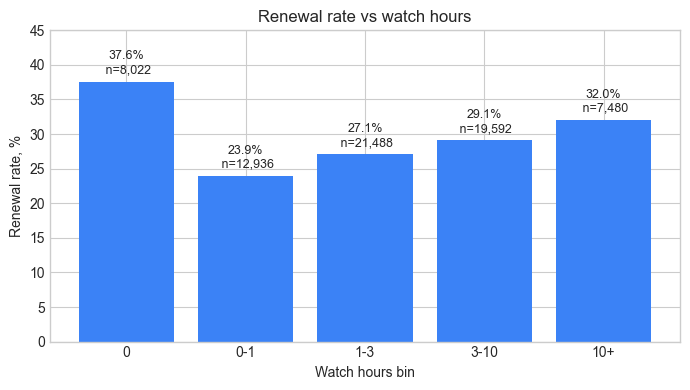

In [5]:
def plot_rate(df, title, xlabel, color="#3b82f6"):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(df["segment"], df["renewal_rate"] * 100, color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Renewal rate, %")
    ax.set_ylim(0, max(45, (df["renewal_rate"].max() * 100) + 5))
    for i, row in df.iterrows():
        ax.text(i, row["renewal_rate"] * 100 + 0.8, f'{row["renewal_rate"]*100:.1f}%\n n={int(row["users"]):,}', ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    return fig, ax

plot_rate(watch_hours, "Renewal rate vs watch hours", "Watch hours bin")
plt.show()

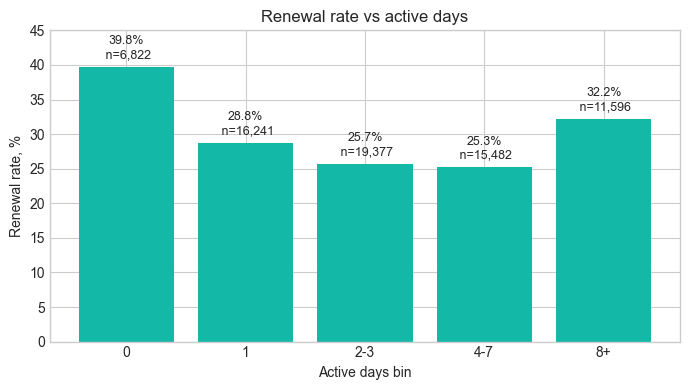

In [6]:
plot_rate(active_days, "Renewal rate vs active days", "Active days bin", color="#14b8a6")
plt.show()

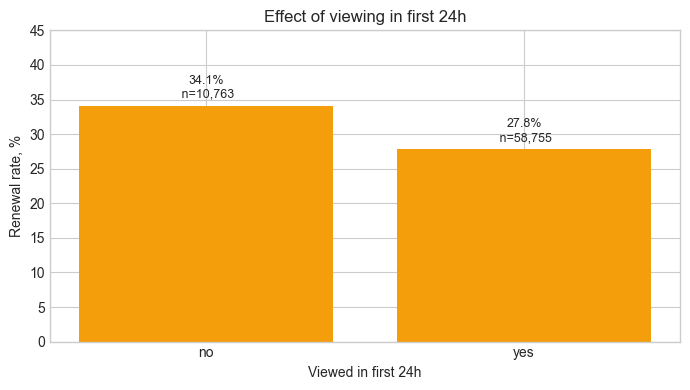

In [7]:
plot_rate(first_24h, "Effect of viewing in first 24h", "Viewed in first 24h", color="#f59e0b")
plt.show()

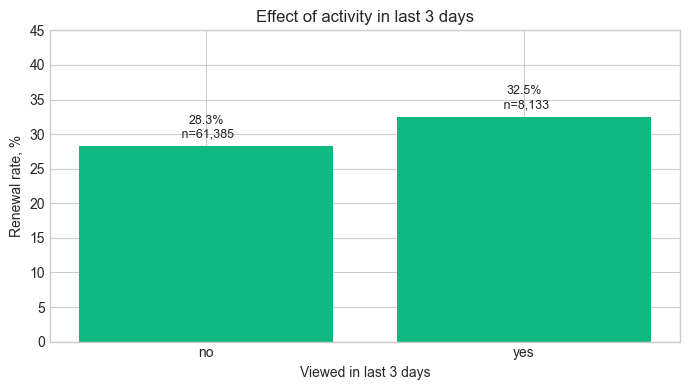

In [8]:
plot_rate(last_3d, "Effect of activity in last 3 days", "Viewed in last 3 days", color="#10b981")
plt.show()

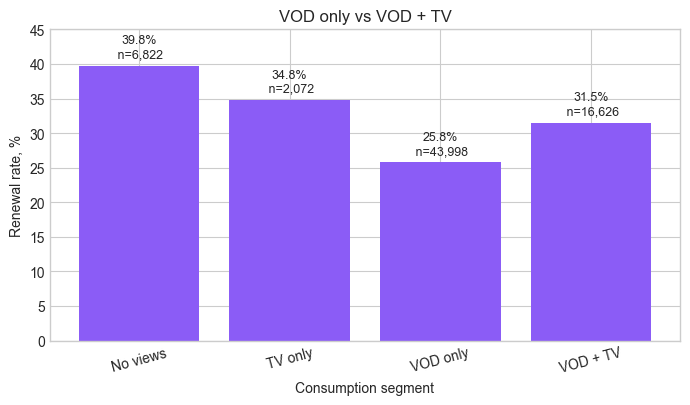

In [9]:
plot_rate(consumption, "VOD only vs VOD + TV", "Consumption segment", color="#8b5cf6")
plt.xticks(rotation=15)
plt.show()

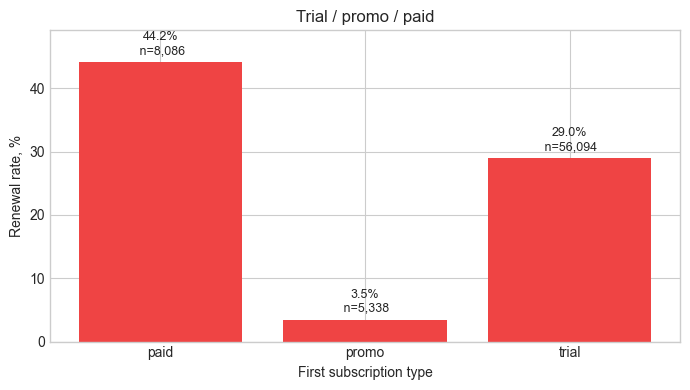

In [10]:
plot_rate(subscription_type, "Trial / promo / paid", "First subscription type", color="#ef4444")
plt.show()

## 4. Summary tables

In [11]:
summary = pd.concat([
    watch_hours.assign(group="watch_hours"),
    active_days.assign(group="active_days"),
    first_24h.assign(group="viewed_first_24h"),
    last_3d.assign(group="viewed_last_3d"),
    consumption.assign(group="consumption_segment"),
    subscription_type.assign(group="subscription_type"),
], ignore_index=True)

summary = summary[["group", "segment", "users", "renewal_rate"]]
summary["renewal_rate_pct"] = (summary["renewal_rate"] * 100).round(2)
summary

,group,segment,users,renewal_rate,renewal_rate_pct
0,watch_hours,0,8022,0.3756,37.5600
1,watch_hours,0-1,12936,0.2394,23.9400
2,watch_hours,1-3,21488,0.2705,27.0500
3,watch_hours,3-10,19592,0.2907,29.0700
4,watch_hours,10+,7480,0.3203,32.0300
5,active_days,0,6822,0.3975,39.7500
6,active_days,1,16241,0.2877,28.7700
7,active_days,2-3,19377,0.2571,25.7100
8,active_days,4-7,15482,0.2526,25.2600
9,active_days,8+,11596,0.3224,32.2400


## Findings

- В когорте 69 518 пользователей, общий `renewed_7d` = 28.8%. Окно наблюдения полное: цензурированных пользователей 0, дата исследования 2026-07-02.
- Watch time не дает простой монотонной картины: у пользователей с `10+` часами renewal rate = 32.0%, что выше сегмента `0-1` час на 8.1 п.п., но сегмент `0` часов имеет 37.6%. Это указывает на сильное влияние типа подписки/пакета или механик автопродления.
- Регулярность тоже нелинейна: `8+` active days дают 32.2%, но сегмент `0` active days = 39.8%. Поэтому active days нельзя интерпретировать без контроля типа подписки.
- Просмотр в первые 24 часа не связан с ростом продления в сыром сравнении: `yes` = 27.8%, `no` = 34.1%. Это против исходной гипотезы и требует сегментации по trial/promo/paid.
- Активность в последние 3 дня выглядит полезнее: пользователи с `viewed_last_3d = 1` имеют 32.5% продления против 28.3% без активности в конце, разница +4.2 п.п.
- VOD + TV лучше, чем VOD only: 31.5% против 25.8%, разница +5.7 п.п. TV only = 34.8%, но сегмент небольшой относительно VOD only.
- Самый сильный фактор в текущих агрегатах - тип первой подписки: paid = 44.2%, trial = 29.0%, promo = 3.5%. Это сильнее любого поведенческого различия и обязательно должно быть контролем в следующей итерации.

Итог: поведение связано с продлением, но сырые зависимости сильно смешаны с типом подписки. Для продуктовой интерпретации наиболее надежные кандидаты: активность в последние 3 дня и сочетание VOD + TV, а не простой общий watch time.

## Product implications

- Если пользователь не посмотрел ничего в первые 24 часа, не стоит автоматически считать его потерянным: сырой renewal rate у этого сегмента выше. Нужно разделить сценарии paid/trial/promo и проверить, нет ли автопродления или пакетной механики.
- Если пользователь не активен в последние 3 дня подписки -> запускать reminder/recommendation-механику ближе к окончанию периода: подборка продолжения сериала, персональные рекомендации, напоминание о недосмотренном контенте.
- Если низкий `active_days` у trial/promo-пользователя -> стимулировать регулярность, а не только первый запуск: серии коротких рекомендаций, подборки на несколько дней, пуши на второй-третий день.
- Если пользователь смотрит только VOD -> можно тестировать предложения live-контента/TV, потому что VOD + TV сегмент имеет более высокий renewal rate, чем VOD only.
- Если пользователь в promo-сегменте -> поведенческие триггеры могут быть недостаточны: promo имеет очень низкое продление, значит нужны отдельные механики конверсии в платную ценность и контроль качества промо-аудитории.
- Следующая аналитическая итерация: повторить графики внутри `trial`, `promo`, `paid` отдельно и построить логистическую регрессию с контролем типа подписки, provider/packet и consumption features.